# Labjournaal BM
## General
Template for labjournaal. See https://jupyter-notebook.readthedocs.io/en/stable/examples/Notebook/Working%20With%20Markdown%20Cells.html for options to use markdown.

**Name:**  
**Title of the experiment:**  
**Starting date:**  
**Expected enddate:**  
**Partner:**  
**Goal of the experiment:**  
**Research question:**  
**Expectations or Hypothesis:**  
**Desired accuracy:**  




In [2]:
#import necessary libraries
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import curve_fit 

# Preparation
 


**Assignments:**  

**Method:**  
**Theory:**  
**Independent variable:**  
**Dependent variable:**  
**Controlled variablen:**  
**Measurement instruments \& Settings:**  
**Procedure:**  
**Setup(drawing or picture):**  
**Notes:**  
**About accuracy:**  


# Execution

In [13]:
# Measurements: Explain the names of variables provide only raw data in np.arrays!
array_3_kort = [10.2,  100.5,  329.4,  323.5,  470, 1000,  4700, 10020, 10040, 33140]
array_5_kort = [10.026,  100.358,  329.42,  323.00,  468.33,  996.63,  4702.2,  10021.8, 10039.4,  33134.00]

array_3_lang = [10.3,  100.5,  329.2,  322.8,  470, 1000, 4700, 10020, 10040, 33150]
array_5_lang = [10.067,  100.397, 329.45,  322.95, 468.35, 996.64,  4702.1,  10021.8,  10039.3,  33134.00]





In [8]:
def uncertainty_meter(x):
    return 0.01*x+0.4
    

In [18]:
#onzekerheid weerstand meting

u_3_kort = uncertainty_meter(array_3_kort[0])
u_5_kort = uncertainty_meter(array_5_kort[0])
u_3_lang = uncertainty_meter(array_3_lang[0])
u_5_lang = uncertainty_meter(array_5_lang[0])


print(u_3_kort)
print(u_5_kort)

print(u_3_lang)
print(u_5_lang)

0.502
0.50026
0.503
0.5006700000000001


In [47]:
#spanningsdeler

U_b = 19.9992
U_ab = 15.0286
U_bc = 4.9687
U_ac = 19.9964
U_b_test = U_ab + U_bc
print(f"De gemete bronspanning is %.5f en de gesommeerde bronspanning is %.5f" %(U_b, U_b_test))

#berekening en bepaling van de verhouding
R_1 = 1e3
R_2 = 330
R_tot = R_1 +R_2

verhouding_U = U_bc/U_ac
berekende_verhouding_U = R_tot

print(f"De gemete verhouding is %.4f en de berekende verhouding is %.4f" %(verhouding_U, berekende_verhouding_U))



De gemete bronspanning is 19.99920 en de gesommeerde bronspanning is 19.99730
De gemete verhouding is 0.2485 en de berekende verhouding is 1330.0000


In [52]:
 #berekening van de stroom door de spanningsmeter

I_ab = U_ab/R_1
I_bc = U_bc/R_2

I_ac = U_ac/R_tot

I_ac_meting = 0.015


print(f"De stroom die volgens de berekeningen door de spanningsdeler loopt is: %.4f A" %(I_ac))
print(f"Dit komt overeen met de gemete waarde van %.4f A" %(I_ac_meting))

#Nu verder met 2V U_b
I_40mA = 0.0149 
I_4mA = 0.01398



De stroom die volgens de berekeningen door de spanningsdeler loopt is: 0.0150 A
Dit komt overeen met de gemete waarde van 0.0150 A


In [117]:
#Diode bepaling voorbereiding

q = 1.602176634e-19
kB = 1.380649e-23
T = 293.15


def current_func(V_D, I0, n):
    return I0 * (np.exp((-q*V_D)/(n*kB*T)))

U_bron = np.arange(0,6.00001,0.25)
U_bron = np.flip(U_bron)

U_R1_m1 = np.array([0.46482, 0.45242, 0.42997, 0.40765, 0.38525, 0.36287, 0.34051, 0.31816, 0.29597, 0.27364, 0.25136, 0.22916, 0.20696, 0.18486, 0.16278, 0.14077, 0.11900, 0.097260, 0.075747, 0.054591, 0.034078, 0.015201, 0.002004, 0.000028, 0])


I_R1_m1 = U_R1_m1/100
#deze meting met 10k resistor ipv 100
U_R1_m2 = np.array ([4.4815, 4.2664, 4.0596, 3.8538, 3.6475, 3.4413, 3.2353, 3.0299, 2.8249, 2.6192, 2.4134, 2.2092, 2.0046, 1.8009, 1.5972, 1.3948, 1.1932, 0.9923, 0.79325, 0.59686, 0.40483, 0.22282, 0.06729, 0.00290, 0])
I_R1_m2 = U_R1_m2/10000

/var/folders/8l/h96stkr51hdbfw1lh2jh3d400000gn/T/ipykernel_92103/2627927015.py:5: RuntimeWarning: divide by zero encountered in log
  plt.plot(U_bron,np.log(I_R1_m2), 'k.')
/var/folders/8l/h96stkr51hdbfw1lh2jh3d400000gn/T/ipykernel_92103/2627927015.py:6: RuntimeWarning: divide by zero encountered in log
  plt.plot(U_bron,np.log(I_R1_m1), 'b.')


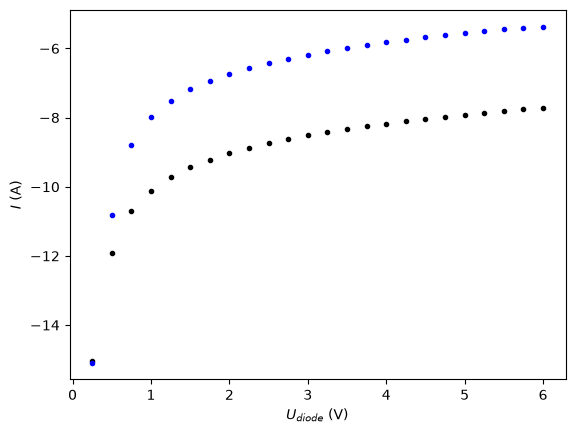

0.21220236013533061 875836371896.1918


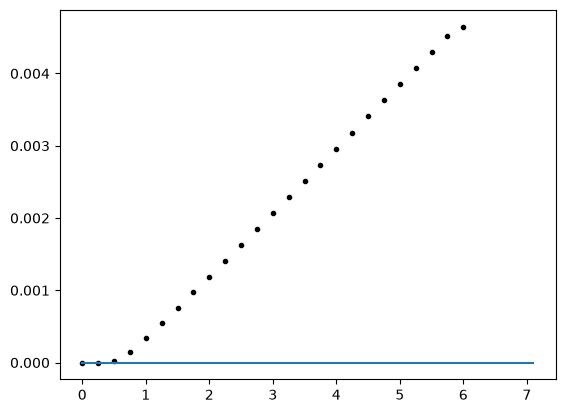

In [118]:
#data meting 1 plotten

plt.figure()

plt.plot(U_bron,np.log(I_R1_m2), 'k.')
plt.plot(U_bron,np.log(I_R1_m1), 'b.')

plt.ylabel("$I$ (A)")
plt.xlabel("$U_{diode}$ (V)")

plt.show()

#curve fitten 
p0 = [1e-9, 1.5]

popt, pcov = curve_fit(current_func, U_bron,U_R1_m1, p0=p0)

perr = np.sqrt(np.diag(pcov))

x_range_fit = np.arange(0,1.2*np.max(U_bron), 0.1)

print(*popt)

plt.figure()

plt.plot(U_bron,I_R1_m1, 'k.')
plt.plot(x_range_fit, current_func(x_range_fit,1e-9,1.5))
plt.show()


**Observations:**  
De onzekerheid is groter geworden naar mate de kabel langer geworden is.
**Notes:**  

# Processing
**Description of processing of raw data into scientific evidence:**


In [ ]:
#Data processing and analysis:


In [ ]:
#Data processing and analysis:


In [ ]:
#Data processing and analysis:


**Describing the pattern in the processed data:**  


In [ ]:
#Calculations of e.a. measurement uncertainties, and providing final answers.


**Notes:**  

# Discussion



# Conclusion

# Additional notes, remarks, explanations, thoughts etc